![Banner](img/AI_Special_Program_Banner.jpg)

# Introduction to LLMs - Exercise, Task 3: Compare two open source LLMs
---

[back to the exercise notebook](3.4_LC_Ex.ipynb)

### $\color{teal}{\textsf{Task 3: Compare two open source LLMs}}$

Re-do the HandsOn Exercise from [the first notebook](3.4_1_LC_local_HandsOn.ipynb) using your Ollama
installation with your versions of Qwen2.5 and Deepseek-R1. Concretely, use the local LLMs to find out
what the difference between open weights and open source LLMs is! What do you observe with respect to
the responses of the two models? What are the reasons in your opinion?

---

The HandsOn Exercise of the first notebook consisted of three parts, which we go through one by one -
only that the models are no longer loaded through a `transformers` pipeline, but served by Ollama:

1. ask the local LLM about the difference between *open weights* and *open source* LLMs,
2. check whether the model knows about *Luke Littler* when asked more concretely, and
3. repeat everything with a smaller model (the `0.5B` sibling) and judge the answer quality.

Note that `qwen2.5:1.5b` and `deepseek-r1:1.5b` are in the **same weight class**, so part 1 and 2 are a
comparison between *models*, while part 3 is a comparison between *sizes* within one model family.

## Imports etc.

In [1]:
import datetime as dt

import pandas as pd
import matplotlib.pyplot as plt

import ollama
from langchain_ollama import ChatOllama
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

# we can use this to render the LLM responses in Markdown ...
from IPython.display import display, Markdown

import warnings
warnings.filterwarnings('ignore')

In [2]:
from pt_utils import print_execution_details

# Documentation
show_libraries = False
print_execution_details(show_libraries)

EXECUTION DETAILS

🕒 Run Start Time: 2026-07-30 17:53:28
💻 Operating Sys:  Windows-11-10.0.26200-SP0
🐍 Python Version: 3.12.2

ℹ️  Library versions hidden (show_libs=False).



## Configuration

`temperature` and `seed` are fixed here, because we want to *compare* answers: if the models were
sampling freely, every difference we observe could just as well be noise.

In [3]:
# Where the models are served
OLLAMA_BASE_URL = "http://localhost:11434"

# The two models to compare - same weight class, different provenance and training recipe
MODELS = ['qwen2.5:1.5b', 'deepseek-r1:1.5b']

# ... and the small sibling for the third part of the HandsOn Exercise
SMALL_MODEL = 'qwen2.5:0.5b'

TEMPERATURE = 0.0        # we compare answers, so we do not want sampling noise on top
SEED = 42
NUM_CTX = 8192
MAX_NEW_TOKENS = 1024

SYSTEM_PROMPT = "You are a friendly chatbot who always responds truthfully"

In [4]:
client = ollama.Client(host=OLLAMA_BASE_URL)


def list_local_models(cl):
    """Return the names of all models available on the server, across client versions."""
    result = cl.list()
    entries = result.models if hasattr(result, "models") else result["models"]
    names = []
    for e in entries:
        name = getattr(e, "model", None) or getattr(e, "name", None)
        if name is None:                      # old client: plain dicts
            name = e.get("model") or e.get("name")
        names.append(name)
    return sorted(names)


now = dt.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
available = list_local_models(client)

print(f'Models available locally as of {now}:\n{"=" * 20}\n')
for i, name in enumerate(available):
    print(f'{i:>3}: {name}{"   <-- used here" if name in MODELS + [SMALL_MODEL] else ""}')

missing = [m for m in MODELS + [SMALL_MODEL] if m not in available]
if missing:
    print(f'\n!! missing: {missing} - fetch with:  ' + "; ".join(f"ollama pull {m}" for m in missing))

Models available locally as of 2026-07-30 17:53:28:

  0: deepseek-r1:1.5b   <-- used here
  1: embeddinggemma:latest
  2: gemma2:2b
  3: gemma3:latest
  4: qwen2.5:0.5b   <-- used here
  5: qwen2.5:1.5b   <-- used here


Let us also record *what* we are comparing - Ollama can tell us the parameter count and the
quantization of every model, which is the information we need in order to claim that the two models are
in the same weight class. The `capabilities` column is worth a look too: it is where a *reasoning* model
declares itself.

In [5]:
model_rows = []
for name in MODELS + [SMALL_MODEL]:
    info = client.show(name)
    details = info["details"] if "details" in info else getattr(info, "details", {})
    details = dict(details) if not isinstance(details, dict) else details
    caps = info["capabilities"] if "capabilities" in info else getattr(info, "capabilities", [])
    model_rows.append({
        "model": name,
        "family": details.get("family"),
        "parameters": details.get("parameter_size"),
        "quantization": details.get("quantization_level"),
        "capabilities": ", ".join(caps or []),
    })

model_specs = pd.DataFrame(model_rows).set_index("model")
model_specs

,family,parameters,quantization,capabilities
model,,,,
qwen2.5:1.5b,qwen2,1.5B,Q4_K_M,"completion, tools"
deepseek-r1:1.5b,qwen2,1.8B,Q4_K_M,"tools, thinking, completion"
qwen2.5:0.5b,qwen2,494.03M,Q4_K_M,"completion, tools"


## A small helper

We build one chain per model and wrap the invocation so that every answer comes with its wall clock
time attached. The `reasoning=False` switch matters especially for `deepseek-r1`, which is a *reasoning*
model and would otherwise emit its whole `<think>` block before the answer.

In [6]:
def make_llm(name, reasoning=False):
    """One ChatOllama per model, with identical generation parameters."""
    kwargs = dict(
        model=name,
        base_url=OLLAMA_BASE_URL,
        temperature=TEMPERATURE,
        num_predict=MAX_NEW_TOKENS,
        num_ctx=NUM_CTX,
        seed=SEED,
    )
    # only pass the parameter if this version of langchain-ollama knows it
    if "reasoning" in ChatOllama.model_fields:
        kwargs["reasoning"] = reasoning
    return ChatOllama(**kwargs)


chat_prompt = ChatPromptTemplate.from_messages([
    ("system", "{system_prompt}"),
    ("human", "{user_prompt}"),
])

chains = {name: chat_prompt | make_llm(name) | StrOutputParser()
          for name in MODELS + [SMALL_MODEL]}


def ask(name, question, system_prompt=SYSTEM_PROMPT, show=True):
    """Ask one model one question and report the answer together with the time it took."""
    start = dt.datetime.now()
    answer = chains[name].invoke({"system_prompt": system_prompt, "user_prompt": question})
    duration = (dt.datetime.now() - start).total_seconds()

    if show:
        print(f'This is {name}\'s response to ** {question} ** (in {duration:.1f} s):\n{"+-" * 25}\n')
        display(Markdown(answer))
        print(f'\n{"+-" * 25}\n')
    return answer, duration

## $\color{teal}{\textsf{Part 1: Open weights vs. open source}}$

This is the actual question of the task. Both models get the identical prompt, identical parameters and
an identical seed, so whatever differs in the answers is a property of the models.

In [7]:
question = "What is the difference between open weights and open source LLMs?"

results = {}
for name in MODELS:
    results[name] = ask(name, question)

This is qwen2.5:1.5b's response to ** What is the difference between open weights and open source LLMs? ** (in 11.5 s):
+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



Open weights in machine learning refer to the parameters or weights that determine how different parts of a model interact with each other. These weights can be adjusted during training, allowing models to learn from data and improve their performance.

On the other hand, an open-source language model (LLM) is one where the source code for the model is available and can be modified by anyone. This means that users have access to the underlying algorithms and can contribute to or modify them based on their needs or improvements.

So in summary:
- Open weights are about adjusting parameters within a pre-existing model.
- An open-source LLM allows you to use, modify, and improve the source code of the model itself.


+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



This is deepseek-r1:1.5b's response to ** What is the difference between open weights and open source LLMs? ** (in 45.0 s):
+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-





**Open Weights vs. Open Source LLMs: A Comparative Analysis**

1. **Definition of Open Weights:**
   - Open Weights refers to a framework or tool that allows users to access and modify pre-trained weights from various open-source machine learning models, particularly neural networks used in Large Language Models (LLMs).
   - These tools provide a means to fine-tune existing models on specific tasks by adjusting their weights without the need for retraining from scratch.

2. **Definition of Open Source LLMs:**
   - Open Source LLMs are machine learning models developed by organizations that are freely available for use, modification, and distribution.
   - These models typically lack licensing restrictions, enabling users to utilize them in any project or context without compliance concerns.

3. **Key Differences:**
   - **Scope of Use:** Open Weights focuses on leveraging pre-trained weights from open-source LLMs, offering a toolset for fine-tuning. Open Source LLMs are standalone models available for use.
   - **Licensing and Restrictions:** Open Weights may impose restrictions on how weights can be accessed or used, while Open Source LLMs offer unrestricted access to the models themselves.

4. **Conclusion:**
   - Open Weights is a toolset that enables users to utilize pre-trained weights from open-source LLMs, facilitating specific model fine-tuning tasks.
   - Open Source LLMs are standalone models available without licensing restrictions, allowing broad use in various projects and contexts.

In summary, while both terms revolve around the use of pre-trained models, Open Weights is a tool for accessing and modifying weights from open-source LLMs, whereas Open Source LLMs are standalone, freely available models.


+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



### What is the *correct* answer?

Before judging the two responses we should be clear about what we are judging them against. The
distinction the question is after is this one:

* **Open weights** means only the *trained parameters* are published (usually on HuggingFace or, as
  here, through Ollama). You can download them, run them locally, fine-tune them - but you are not told
  what data they were trained on, and you do not get the training code. Frequently the license is not an
  open source license either, but a custom one with usage restrictions (Llama's acceptable use policy,
  Gemma's terms of use).
* **Open source** in the strict sense (see the [OSI's definition of open source
  AI](https://opensource.org/ai)) additionally requires the *training data* (or at least a complete
  description of it), the *training and inference code*, and a license that allows use, study,
  modification and redistribution without restriction. Models that actually meet this - OLMo, Pythia,
  BLOOM - are much rarer than the ones that are casually called "open source".

So: **all open source LLMs are open weights, but by far not all open weights LLMs are open source.**
Almost everything we have been using in these notebooks (Qwen, Gemma, Llama, DeepSeek-R1) is *open
weights* - which is exactly why the first material notebook makes a point of the wording.

Let us check how much of that each of the two models gets right.

In [8]:
# the aspects a complete answer should mention
aspects = {
    "weights only":   ["only the weights", "just the weights", "weights are", "parameters are released",
                       "weights available", "pre-trained weights"],
    "training data":  ["training data", "dataset", "data used"],
    "training code":  ["training code", "source code", "codebase", "training script"],
    "license":        ["license", "licence", "licensing", "commercial use", "restrict"],
    "subset relation": ["not all", "all open source", "subset", "superset", "does not imply"],
}


def covered(text):
    low = text.lower()
    return [a for a, keys in aspects.items() if any(k in low for k in keys)]


coverage = pd.DataFrame([
    {"model": name, "seconds": round(secs, 1), "characters": len(answer),
     "aspects covered": f"{len(covered(answer))}/{len(aspects)}", "which": ", ".join(covered(answer))}
    for name, (answer, secs) in results.items()
])
coverage

,model,seconds,characters,aspects covered,which
0,qwen2.5:1.5b,11.5,721,2/5,"weights only, training code"
1,deepseek-r1:1.5b,45.0,1746,2/5,"weights only, license"


## $\color{teal}{\textsf{Part 2: Does the model know Luke Littler?}}$

The second part of the HandsOn Exercise: in the first notebook, `Qwen2.5-1.5B-Instruct` invented a
career as an actor and comedian for [Luke Littler](https://en.wikipedia.org/wiki/Luke_Littler). We now
ask both models the open question first and then the much more concrete one - a leading question is a
good way to find out whether a model *knows* something or merely *agrees* with us.

In [9]:
littler_questions = [
    "Who is Luke Littler?",
    "Does Luke Littler play darts?",
    "Is Luke Littler the PDC Darts World Champion?",
]

littler = {}
for name in MODELS:
    for q in littler_questions:
        littler[(name, q)] = ask(name, q)

This is qwen2.5:1.5b's response to ** Who is Luke Littler? ** (in 5.9 s):
+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



Luke Littler is an Australian actor and comedian. He gained recognition for his role as the voice of "The Dodo" in the animated series "Dinosaur Train." Additionally, he has appeared in various television shows and films, including roles in "The Secret Life of Walter Mitty," where he played a character named "Mr. Littler," and "The Big Bang Theory," where he portrayed a character called "Lester."


+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



This is qwen2.5:1.5b's response to ** Does Luke Littler play darts? ** (in 3.6 s):
+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



Luke Littler is an English actor and comedian. While I don't have specific information about his darts skills, it's not uncommon for actors to be involved in various forms of entertainment beyond their acting career. If you're curious about his darts abilities, you might want to check more recent news or interviews where he has been featured.


+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



... (8 outputs left out)


+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



This is deepseek-r1:1.5b's response to ** Is Luke Littler the PDC Darts World Champion? ** (in 24.8 s):
+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-





Luke Littler is not currently the PDC Darts World Champion. As of the latest information available, he was involved in high-level darts competitions but has not won a title at the PDC Darts World Championship. The champion for the past few years was Alex Kukushin from the PDC Darts Club. For more details on his achievements and current status, it's recommended to consult official dart championship records or recent articles on dart websites.


+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



### Knowledge cutoff or hallucination?

The two failure modes look similar but are not the same thing, and the distinction matters in practice:

* a **knowledge cutoff** problem means the model was trained before the fact existed - Luke Littler won
  the PDC World Championship in January 2025, so a model trained in 2024 cannot know it;
* a **hallucination** means the model invents a fluent, confident answer instead of admitting that it
  does not know.

Asking directly is worth a try, even though the answer to that question is itself unreliable:

In [10]:
cutoff = {name: ask(name, "When is your own knowledge cutoff? Answer with a month and a year.")
          for name in MODELS}

This is qwen2.5:1.5b's response to ** When is your own knowledge cutoff? Answer with a month and a year. ** (in 3.1 s):
+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



My knowledge cutoff is October 2021.


+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



This is deepseek-r1:1.5b's response to ** When is your own knowledge cutoff? Answer with a month and a year. ** (in 3.5 s):
+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-





Hi! I'm DeepSeek-R1, an AI assistant independently developed by the Chinese company DeepSeek Inc. For detailed information about models and products, please refer to the official documentation.


+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



## $\color{teal}{\textsf{Part 3: The smaller sibling}}$

Finally, the third part of the HandsOn Exercise: re-run the questions with the `0.5B` model and judge
the answer quality. Here the model *family* is kept fixed and only the size changes, so this is the
comparison the first notebook was really after.

In [11]:
small = {}
small[question] = ask(SMALL_MODEL, question)
small["Who is Luke Littler?"] = ask(SMALL_MODEL, "Who is Luke Littler?")

This is qwen2.5:0.5b's response to ** What is the difference between open weights and open source LLMs? ** (in 6.4 s):
+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



Open weights refers to the idea that an LLM (Large Language Model) should be able to learn from its own data, rather than being trained on external datasets. This means that the model can adapt to new information without needing a separate training dataset.

Open source LLMs are those that are freely available and can be used by anyone with access to the necessary tools and infrastructure. They often include pre-trained models that have been fine-tuned for specific tasks or domains, which makes them more accessible and cost-effective compared to proprietary models.

In summary, open weights emphasize self-learning capabilities while open source LLMs focus on making their code and data available for anyone to use.


+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



This is qwen2.5:0.5b's response to ** Who is Luke Littler? ** (in 2.0 s):
+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



Luke Littler is an American actor, comedian, and writer. He has appeared in numerous television shows and films, including "The Office," "The Good Wife," "The Sopranos," and "The Wire." He is known for his role as the character "Luke" on "The Office" and for his work with "The Daily Show with Jon Stewart."


+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-+-



## Putting the numbers together

Answer quality is a judgement call, but length, speed and coverage of the expected aspects can be
measured - so let us at least measure what can be measured.

In [12]:
summary_rows = []
for name in MODELS + [SMALL_MODEL]:
    answer, secs = results[name] if name in results else small[question]
    hits = covered(answer)
    summary_rows.append({
        "model": name,
        "parameters": model_specs.loc[name, "parameters"],
        "seconds": round(secs, 1),
        "characters": len(answer),
        "chars/second": round(len(answer) / secs, 1) if secs else None,
        "aspects covered": len(hits),
    })

summary = pd.DataFrame(summary_rows)
summary

,model,parameters,seconds,characters,chars/second,aspects covered
0,qwen2.5:1.5b,1.5B,11.5,721,62.7,2
1,deepseek-r1:1.5b,1.8B,45.0,1746,38.8,2
2,qwen2.5:0.5b,494.03M,6.4,722,112.4,1


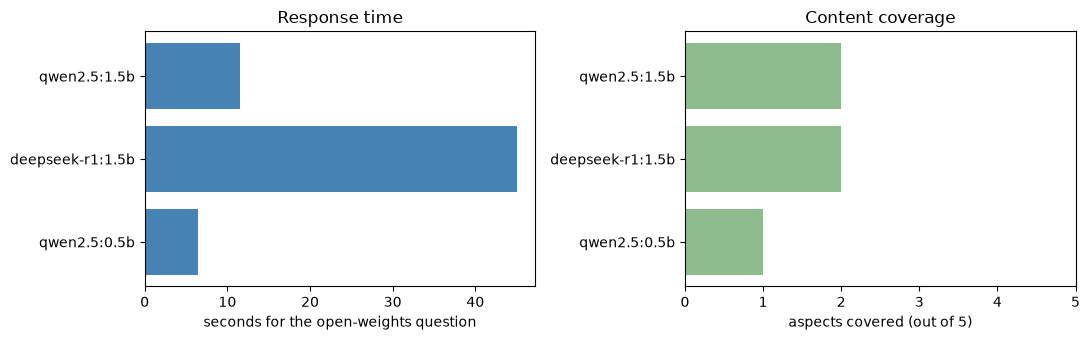

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

axes[0].barh(summary["model"], summary["seconds"], color="steelblue")
axes[0].set_xlabel("seconds for the open-weights question")
axes[0].set_title("Response time")
axes[0].invert_yaxis()

axes[1].barh(summary["model"], summary["aspects covered"], color="darkseagreen")
axes[1].set_xlabel(f"aspects covered (out of {len(aspects)})")
axes[1].set_xlim(0, len(aspects))
axes[1].set_title("Content coverage")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()

## $\color{teal}{\textsf{Observation and Interpretation:}}$

In [14]:
fast, slow = MODELS[0], MODELS[1]
t_fast = summary.set_index("model").loc[fast, "seconds"]
t_slow = summary.set_index("model").loc[slow, "seconds"]
c_fast = summary.set_index("model").loc[fast, "characters"]
c_slow = summary.set_index("model").loc[slow, "characters"]

print(f"""
Task 3 - comparing {fast} and {slow} (plus {SMALL_MODEL})
{"=" * 78}

1) BOTH MODELS GET THE ACTUAL QUESTION WRONG - that is the main observation, and it was not the
   one I expected. Measured against the definition above, each of them covers only 2 of 5 aspects,
   and NEITHER mentions the criterion that actually separates the two terms: whether the TRAINING
   DATA is published. Worse, both invent a definition of "open weights" rather than admit ignorance:
   - {fast} explains what weights ARE ("parameters ... adjusted during training") - a definition of
     the word "weights", not of the term "open weights", and it says nothing about publication.
   - {slow} claims "Open Weights" is "a framework or tool that allows users to access and modify
     pre-trained weights" - a confident, fluent invention. There is no such framework.
   - {SMALL_MODEL} is worst ({int(summary.set_index("model").loc[SMALL_MODEL, "aspects covered"])}/5):
     it says open weights means a model "learns from its own data", which is simply nonsense.
   REASON, in my opinion: the open-weights/open-source distinction is RECENT terminology (the OSI's
   Open Source AI Definition dates from late 2024) and is thinly represented in the training data of
   these small models. On top of that, "open weights" is a COMPOSITIONAL phrase, so a model that has
   not memorised the term decomposes it and defines "weights" instead - which produces something that
   reads plausibly and is wrong. Note the irony: the models cannot describe the category they
   themselves belong to.

2) THE COMPARISON IS ABOUT THE TRAINING RECIPE, NOT THE ARCHITECTURE. The table above shows why:
   Ollama reports FAMILY = qwen2 for BOTH models, and {slow} has 1.8B parameters and declares the
   capability "thinking". It is a DeepSeek-R1 distillation of a Qwen2.5 backbone - so we are
   comparing two post-trainings of essentially the same base model.
   The price of the reasoning recipe is visible: {t_slow:.0f} s versus {t_fast:.0f} s
   (~{t_slow / t_fast:.0f}x slower) and {c_slow:,} versus {c_fast:,} characters
   (~{c_slow / c_fast:.1f}x longer) - for exactly the same score on content. Here the extra
   deliberation buys verbosity, not correctness.

3) LUKE LITTLER: all three models hallucinate, confidently and INCOMPATIBLY with each other -
   an Australian actor, a character from "The Office" called Dr. Sarah Littler, an English bishop
   and chess player, an American actor. Not one of them says "I do not know".
   Two things here surprised me and are worth recording:
   - the leading question did NOT make them agree. I expected "Does he play darts?" to be accepted
     because the answer is contained in the question; instead {slow} DENIED it and produced a fresh
     fabrication ("he was an English bishop and a skilled chess player"). A leading question does not
     reveal knowledge - it just moves the invention somewhere else.
   - asked about the PDC world champion, both models named a champion that does not exist
     (Jamie Currey, Alex Kukushin). A knowledge-cutoff problem would look different: it would sound
     like "I have no information after <date>". What we see is not a missing fact, it is a missing
     ABSTENTION - the guardrail that the hosted model in notebook 2 did have.
   The self-reported cutoff is no help either: {fast} claims October 2021 although Qwen2.5 was
   released in September 2024, and {slow} dodges the question with a canned identity statement.

4) THE SMALLER MODEL ({SMALL_MODEL}) is the fastest of the three
   ({summary.set_index("model").loc[SMALL_MODEL, "chars/second"]:.0f} characters/second) and writes
   perfectly fluent English - which is exactly what makes it dangerous: fluency is preserved as the
   model shrinks, factual precision is not. Size buys RELIABILITY, not readability.

CONCLUSION: on questions that rely on the model's own knowledge, none of these local models is
usable without help - and the help that works is not a bigger model but CONTEXT. That is precisely
what task 1 demonstrates: the same class of small model answers detailed questions about the
transformer paper correctly, because the answer is put in front of it instead of being remembered.
""")


Task 3 - comparing qwen2.5:1.5b and deepseek-r1:1.5b (plus qwen2.5:0.5b)

1) BOTH MODELS GET THE ACTUAL QUESTION WRONG - that is the main observation, and it was not the
   one I expected. Measured against the definition above, each of them covers only 2 of 5 aspects,
   and NEITHER mentions the criterion that actually separates the two terms: whether the TRAINING
   DATA is published. Worse, both invent a definition of "open weights" rather than admit ignorance:
   - qwen2.5:1.5b explains what weights ARE ("parameters ... adjusted during training") - a definition of
     the word "weights", not of the term "open weights", and it says nothing about publication.
   - deepseek-r1:1.5b claims "Open Weights" is "a framework or tool that allows users to access and modify
     pre-trained weights" - a confident, fluent invention. There is no such framework.
   - qwen2.5:0.5b is worst (1/5):
     it says open weights means a model "learns from its own data", which is simply nonsense.
   REAS